# PSA の位置の較正: バタフライマップの 64 点(`position_haNN.csv`)

`PSA_Calibration` は、ch ごとのバタフライマップ(`x_hg`-`y_hg`)の 64 個のスポットと、そのピクセル番号 (n, m) を
`calib/psa/position_haNN.csv` から読み、その 64 点を通る薄板スプラインで (`x_hg`, `y_hg`) → (n, m) に直します。
このファイルを較正のランから作るのが `scripts/calib/make_psa_position.py` です。EricaNext_try のゲインマップやドリフト速度と同じく、
**較正はスクリプトで作ってファイルに置き、チェーンはそれを読むだけ**です。

| 手順 | 中身 |
|---|---|
| 1. ヒットを選ぶ | ピークがトリガーの時刻(`--peak-id-min 26 --peak-id-max 29`)、`hg` が 3 万〜50 万、飽和していない(`--skip-saturated`) |
| 2. 列 | x への射影(平滑化)の、目立つ順に 8 つの山。列の境目は隣との中点 |
| 3. 行 | 列ごとの y への射影の、2 階微分の目立つ順に 8 つ(中央の列の上下の行は山ではなく、列の端の斜面の「肩」なので) |
| 4. (n, m) | 列と行の順番。スポットの位置は (列, 行) |
| 5. 確かめる | 64 点の薄板スプラインで直したとき、8 × 8 に入るヒットの割合。`--min-frac`(0.9)未満の ch は書かない |
| 6. 書く | `position_haNN.csv`(`#` の行に入力と条件、`ch,No,x,y,z,n,m`)と、確認の図 `qa/position_haNN.png` |

これが `--method grid`(既定)です。`--method localmax` は `peak_search.py` と同じ方法(平滑化した 2 次元の図の極大を高い順に 64 個)で、
同じヒストグラムで `peak_search.py` と同じ 64 点になります。ただし縦に長い中央のスポットから何個も極大を拾い、端の列が 64 個から押し出されます。
これは統計を増やしても直りません(下の 3 節で比べる)。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
CALIB_SCRIPTS = REPO / "scripts" / "calib"
sys.path.insert(0, str(CALIB_SCRIPTS))
CACHE = REPO / "tutorials" / "cache"      # チェーンの出力の置き場(git には入れない)
CACHE.mkdir(exist_ok=True)
CAL_OUT = CACHE / "calib_psa"              # このノートブックで作る較正ファイル(calib/psa は上書きしない)
CAL_OUT.mkdir(exist_ok=True)
PYTHON = "/usr/bin/python3"                # scripts/calib を動かす Python(numpy, scipy, PyROOT)
DATA = Path(os.environ.get("SMILE3_PSA_CAL_DATA", "/mnt/d/UVSOR2026_late"))

def run(cmd, show=True):
    """コマンドを実行し、出力を表示する"""
    print(" ".join(str(c) for c in cmd))
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if show:
        print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
    r.check_returncode()

def chain(run_name, out, *args):
    """UVSOR のラン 1 本を smile3_psa で流す(出力が既にあれば何もしない)"""
    if out.exists():
        return out
    run([sys.executable, RUN_CHAIN, "smile3_psa", "-o", out, "--data-dir", DATA / "killua" / run_name,
         "--set", "PSA_ReadData.extra_data_dirs=" + json.dumps([str(DATA / "calltt" / run_name)]), *args], show=False)
    return out

## 1. データ

2026-11-03 の UVSOR での HA_cal のランを使います(解析用の計算機の D ドライブ `/mnt/d/UVSOR2026_late`。
ほかの場所にあるときは環境変数 `SMILE3_PSA_CAL_DATA`)。ランの記録は Notion の
「SMILE-3 FM UVSOR 試験(2026-11-03)データ確認と HA_cal の解析」にあります。

| ラン | 線源 | 温度 | 中身 |
|---|---|---|---|
| run01〜11 | Cs-137 | 39〜49 °C | 1 ランは約 2 分。多くは storage の OOM で途中で止まった(.dat.tmp が残る) |
| run12 | Co | 47〜49 °C | 4 時間。ha02 で 1 ch あたり 130〜160 万ヒット。ほぼ全部がトリガーの時刻に入る。ha04 は無い |

チェーンの出力は 1 ランに 1 つ、`tutorials/cache/psa_<ラン>.root` に置き、既にあれば流し直しません
(Cs は 1 ランに 1〜4 分、run12 は約 2 時間)。

位置の較正には、統計が多く、ほぼ全部のヒットがトリガーの時刻に入る **run12(Co)** を使います。
run12 の `.dat` は `part0`〜`part4` のサブディレクトリに分かれているので、`PSA_ReadData.recursive: true` で読みます
(killua の part0 と part2 には同じファイルのコピーが重なっていて、警告を出して 1 つだけ使う)。

In [2]:
ROOT_CO = chain("20261103_run12", CACHE / "psa_20261103_run12.root", "--set", "PSA_ReadData.recursive=true")
print(ROOT_CO.name, f"{ROOT_CO.stat().st_size / 1e9:.1f} GB")

psa_20261103_run12.root 11.4 GB


## 2. 64 点を探す

ha02 を作ります(全ボードなら `--boards` を外す。全ボードで 3 分ほど)。出力は `tutorials/cache/calib_psa/` です。

In [3]:
CUTS = ["--peak-id-min", "26", "--peak-id-max", "29", "--skip-saturated"]
run([PYTHON, CALIB_SCRIPTS / "make_psa_position.py", ROOT_CO, "-o", CAL_OUT, "--boards", "2", "--overwrite", *CUTS])
print("".join(l for l in open(CAL_OUT / "position_ha02.csv") if l.startswith("#") and not l.startswith("# input")))

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_psa_position.py /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run12.root -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa --boards 2 --overwrite --peak-id-min 26 --peak-id-max 29 --skip-saturated


ha02: /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/position_ha02.csv
    ch0: 812704 hits, 97.9 % of them in 8x8 after the correction
    ch1: 908571 hits, 98.1 % of them in 8x8 after the correction
    ch2: 770373 hits, 96.2 % of them in 8x8 after the correction
    ch3: 829396 hits, 97.4 % of them in 8x8 after the correction
    ch4: 867360 hits, 95.2 % of them in 8x8 after the correction
    ch5: 1028247 hits, 97.8 % of them in 8x8 after the correction

# made by scripts/calib/make_psa_position.py, 2026-11-05T18:03:09
# hits: hg >= 30000.0 && hg <= 500000.0 && peak_id >= 26 && peak_id <= 29 && !satu_h && !satu_l && (board == 2)
# method grid: col_sep 0.03, row_sep 0.006, grid_smooth 1.5, row_smooth 2.5, min_rel 0.1; z = hits in the cell
# ch0: 812704 hits, 97.9 % of them in 8x8 after the correction
# ch1: 908571 hits, 98.1 % of them in 8x8 after the correction
# ch2: 770373 hits, 96.2 % of them in 8x8 after the correction
# ch3: 829396 hits, 97.4 % of them i

上の段がバタフライマップと 64 点(数字は n m)、下の段が補正後の位置です。点の集まりが 8 × 8 のマス目の中央に並べば使えます。

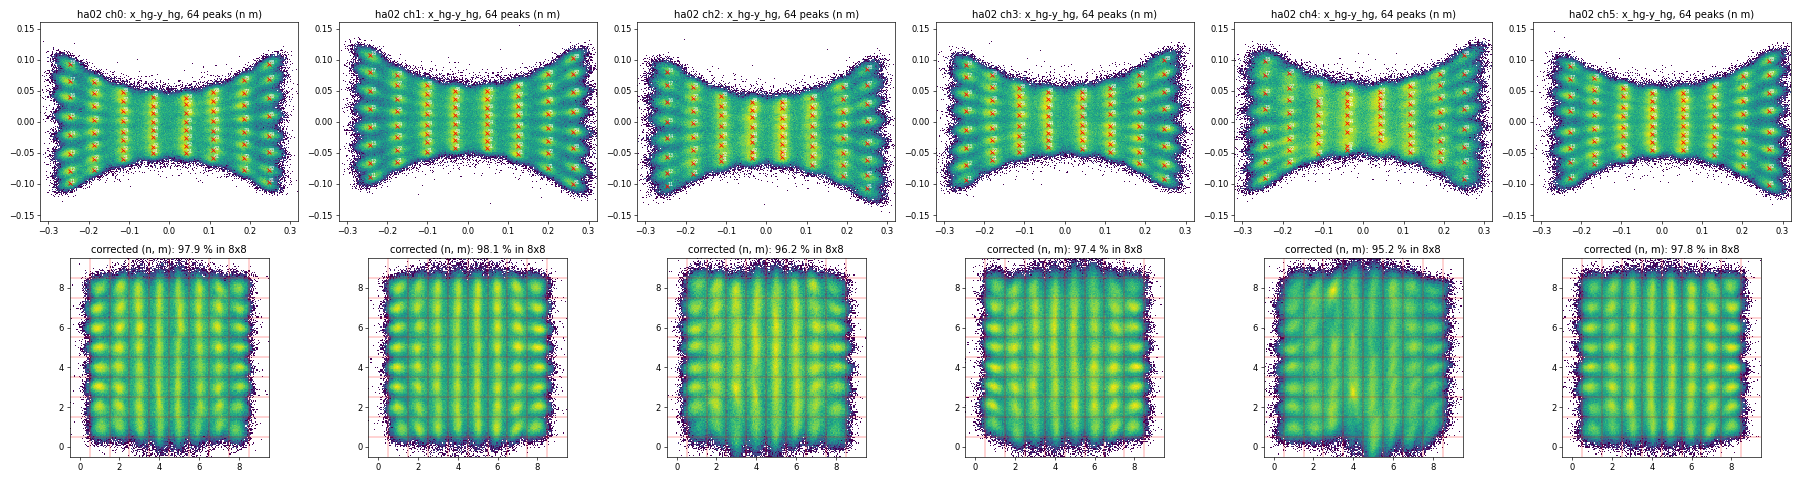

In [4]:
display(Image(filename=str(CAL_OUT / "qa" / "position_ha02.png")))

## 3. `localmax`(peak_search.py と同じ方法)と比べる

同じヒットで `--method localmax` にすると、中央の列に点が固まり、補正後の位置がマス目にそろいません。

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_psa_position.py /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run12.root -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/localmax --boards 2 --overwrite --method localmax --min-frac 0 --peak-id-min 26 --peak-id-max 29 --skip-saturated


ha02: /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/localmax/position_ha02.csv
    ch0: 812704 hits, 94.0 % of them in 8x8 after the correction
    ch1: 908571 hits, 97.5 % of them in 8x8 after the correction
    ch2: 770373 hits, 88.5 % of them in 8x8 after the correction
    ch3: 829396 hits, 92.0 % of them in 8x8 after the correction
    ch4: 867360 hits, 84.4 % of them in 8x8 after the correction
    ch5: 1028247 hits, 97.2 % of them in 8x8 after the correction



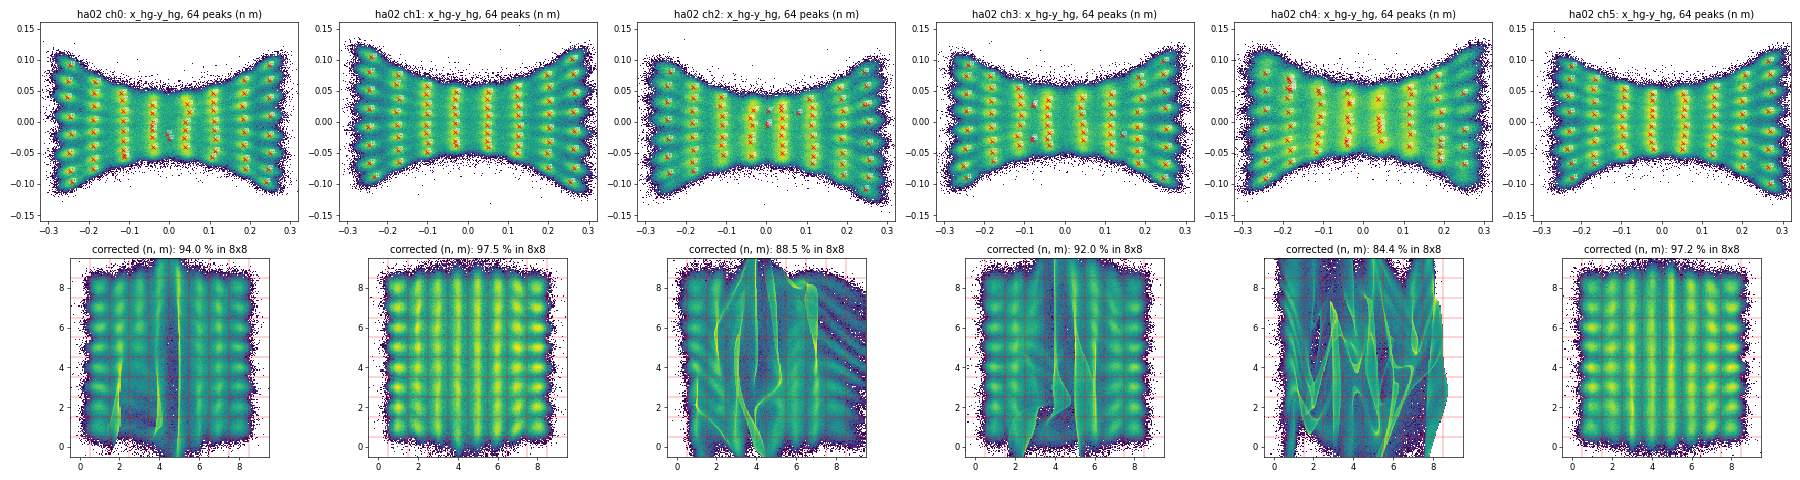

In [5]:
LM = CAL_OUT / "localmax"
run([PYTHON, CALIB_SCRIPTS / "make_psa_position.py", ROOT_CO, "-o", LM, "--boards", "2", "--overwrite", "--method", "localmax",
     "--min-frac", "0", *CUTS])
display(Image(filename=str(LM / "qa" / "position_ha02.png")))

## 4. うまくいかない ch

ha01 の ch4 は、バタフライマップそのものがにじんでいて、補正後に 8 × 8 に入るのが 84% しかありません。`--min-frac 0.9` で書かれません
(その ch はピクセルを求めない)。Notion には、ha00 の ch4、ha01 の ch3 などで LG のペデスタルが跳んでノイズで埋まる時間があったと書かれています。

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_psa_position.py /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_20261103_run12.root -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa --boards 1 --overwrite --peak-id-min 26 --peak-id-max 29 --skip-saturated


ha01: /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/position_ha01.csv
    ch0: 265998 hits, 95.4 % of them in 8x8 after the correction
    ch1: 487317 hits, 96.8 % of them in 8x8 after the correction
    ch2: 660002 hits, 97.2 % of them in 8x8 after the correction
    ch3: 372460 hits, 96.3 % of them in 8x8 after the correction
    ch4: 365800 hits, only 83.6 % in 8x8 after the correction (< --min-frac 0.9); ch not written
    ch5: 364349 hits, 96.0 % of them in 8x8 after the correction



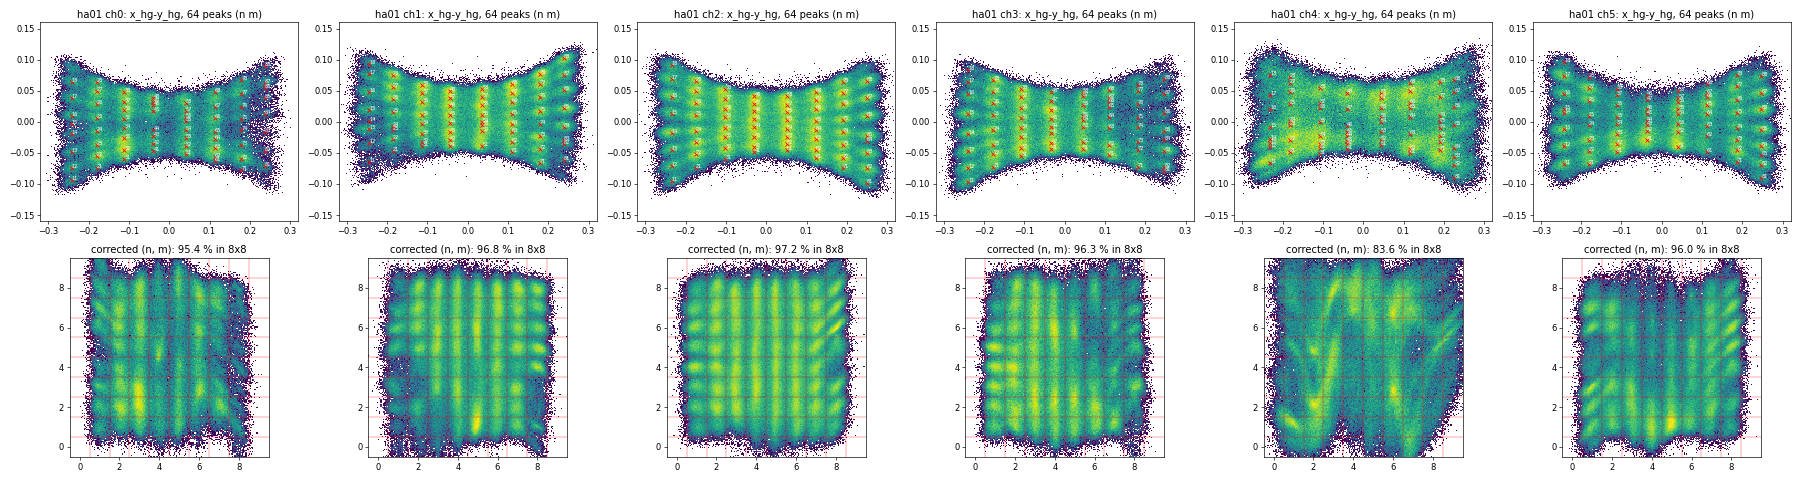

In [6]:
run([PYTHON, CALIB_SCRIPTS / "make_psa_position.py", ROOT_CO, "-o", CAL_OUT, "--boards", "1", "--overwrite", *CUTS])
display(Image(filename=str(CAL_OUT / "qa" / "position_ha01.png")))

## 5. 使う

確認して使えると判断したら、`calib/psa/` に書きます(前のものは git の履歴で戻せる)。今の `calib/psa/position_haNN.csv` は、
この手順で run12 から全ボードを作ったものです(ha04 だけは run12 に無いので、前の peak_search の仮のもの)。

```bash
/usr/bin/python3 scripts/calib/make_psa_position.py tutorials/cache/psa_20261103_run12.root -o calib/psa --overwrite \
    --peak-id-min 26 --peak-id-max 29 --skip-saturated
```